In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
##import libraries
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib as mpl
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
heart = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Data Analytics/heart.csv')

heart.columns = ['Age', 'Sex', 'Chest Pain Type', 'Resting Blood Pressure', 'Cholesterol', 'Fasting Blood Sugar', 'Resting ECG Results', 'Maximum Heart Rate Achieved', 'Exercise-Induced Angina', 'Previous Peak', 'Slope of Peak Exercise', 'Number of Major Vessels Coloured', 'Thalassemia Results', 'Output']

heart.head(303)

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Maximum Heart Rate Achieved,Exercise-Induced Angina,Previous Peak,Slope of Peak Exercise,Number of Major Vessels Coloured,Thalassemia Results,Output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [ ]:
heart.describe()

,Age,Sex,Chest Pain Type,Resting Blood Pressure,Cholesterol,Fasting Blood Sugar,Resting ECG Results,Maximum Heart Rate Achieved,Exercise-Induced Angina,Previous Peak,Slope of Peak Exercise,Number of Major Vessels Coloured,Thalassemia Results,Output
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
x = heart.drop(['Output'],axis=1) # setting to axis 1 means the output column is removed
y = heart['Output']

In [ ]:
# splitting train and test data set
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [ ]:
# splitting validation data set from test set
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size=0.5, random_state=42)

In [ ]:
#Normalisation
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
# scaler = StandardScaler()
scaler = MinMaxScaler()
scaled_x_train = scaler.fit_transform(x_train)
print(len(scaled_x_train))
print(scaled_x_train)

242
[[0.27083333 1.         0.33333333 ... 1.         0.         0.66666667]
 [0.60416667 1.         0.         ... 1.         0.         1.        ]
 [0.35416667 1.         0.66666667 ... 0.5        0.         0.66666667]
 ...
 [0.83333333 1.         1.         ... 0.5        0.25       0.66666667]
 [0.35416667 1.         0.         ... 1.         0.         1.        ]
 [0.70833333 0.         0.33333333 ... 1.         0.5        0.66666667]]


In [ ]:
# Normalising validation set
scaled_x_val = scaler.fit_transform(x_val)
print(scaled_x_val)
print(len(scaled_x_val))

[[ 0.38874494  0.54006172 -0.81114746  1.13443409  0.71947402 -0.38490018
  -1.03279556 -1.51431663  1.10194633 -0.40858798 -0.54592083  0.22429447
  -1.73807954]
 [ 0.38874494  0.54006172  1.37542395  1.13443409 -1.29457199 -0.38490018
   0.96824584  1.00343126 -0.90748521  0.25805557  0.99258333 -0.7690096
  -0.32017255]
 [-0.18511664  0.54006172 -0.81114746 -0.31985924 -0.62322332  2.59807621
   0.96824584  0.2724722   1.10194633 -0.14193056 -0.54592083 -0.7690096
  -3.15598654]
 [ 0.84783419  0.54006172 -0.81114746  0.47339167 -0.56727759 -0.38490018
  -1.03279556 -0.45848687  1.10194633  0.45804863  0.99258333  0.22429447
   1.09773445]
 [-1.56238441  0.54006172 -0.81114746 -1.50973559 -1.31322056 -0.38490018
  -1.03279556 -1.43309896  1.10194633  0.52471298 -0.54592083 -0.7690096
   1.09773445]
 [ 0.96260651 -1.8516402  -0.81114746  1.79547651 -1.36916628 -0.38490018
  -1.03279556 -0.17422501 -0.90748521  3.32461587 -2.084425    2.21090261
   1.09773445]
 [ 1.42169577 -1.8516402 

In [ ]:
scaled_x_test = scaler.fit_transform(x_test)
print(len(scaled_x_test))

30


In [ ]:
## Creating the model
model = Sequential()
# model.add(Dense(6,activation='relu'))
# model.add(Dense(10,activation=''))
# model.add(Dense(8,activation="relu"))
# model.add(Dense(6,activation="relu"))
# model.add(Dense(4,activation="relu"))
model.add(Dense(1, activation="sigmoid"))

In [ ]:
## defining the optimiser and loss function
model.compile(loss='binary_crossentropy', metrics=['accuracy'])
# ## training the model
history = model.fit(x=scaled_x_train,y=y_train,
          validation_data=(scaled_x_val,y_val),
          epochs=50,verbose=0)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 1)                 14        
                                                                 
Total params: 14 (56.00 Byte)
Trainable params: 14 (56.00 Byte)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
train_acc = model.evaluate(scaled_x_train, y_train, verbose=0)[1]
test_acc = model.evaluate(scaled_x_test, y_test, verbose=0)[1]
# # print(train_acc)
# # print(test_acc)
print("Train accuracy of keras neural network: {}".format(round((train_acc * 100), 2)))
print("Test accuracy of keras neural network: {}".format(round((test_acc * 100),2)))

Train accuracy of keras neural network: 83.88
Test accuracy of keras neural network: 83.33


<Axes: >

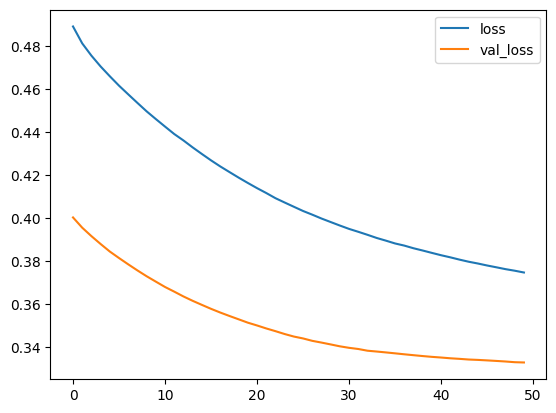

In [ ]:
graf=pd.DataFrame(history.history)
graf=graf.drop(["val_accuracy","accuracy"],axis=1)
graf.plot()

In [ ]:
y_pred = model.predict(scaled_x_test)
y_pred=(y_pred>0.5).astype(int)
print("Accuracy is",accuracy_score(y_test,y_pred))

1/1 [==============================] - 0s 110ms/step
Accuracy is 0.8333333333333334


In [ ]:
model_1 = Sequential()
model_1.add(Dense(13,activation='relu'))
model_1.add(Dense(8,activation='relu'))
model_1.add(Dense(8,activation="relu"))
model_1.add(Dense(6,activation="relu"))
model_1.add(Dense(4,activation="relu"))
model_1.add(Dense(1))


In [ ]:
## defining the optimiser and loss function
model_1.compile(optimizer='adam',loss='binary_crossentropy', metrics=['accuracy'])
## training the model
history1 = model_1.fit(x=scaled_x_train,y=y_train,
          validation_data=(scaled_x_val,y_val),
          batch_size=2,epochs=50,verbose=0)
model_1.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1 (Dense)             (None, 13)                182       
                                                                 
 dense_2 (Dense)             (None, 8)                 112       
                                                                 
 dense_3 (Dense)             (None, 8)                 72        
                                                                 
 dense_4 (Dense)             (None, 6)                 54        
                                                                 
 dense_5 (Dense)             (None, 4)                 28        
                                                                 
 dense_6 (Dense)             (None, 1)                 5         
                                                                 
Total params: 453 (1.77 KB)
Trainable params: 453 (1.7

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', mode='min', verbose = 1, patience = 15)

In [ ]:
model_1.compile(optimizer='adam',loss='binary_crossentropy', metrics=['accuracy'])
history_1= model_1.fit(x=scaled_x_train, y=y_train, validation_data=(scaled_x_val, y_val), epochs=1000, verbose=0, batch_size=45, callbacks=[early_stopping])
model_1.summary()

Epoch 47: early stopping
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1 (Dense)             (None, 13)                182       
                                                                 
 dense_2 (Dense)             (None, 8)                 112       
                                                                 
 dense_3 (Dense)             (None, 8)                 72        
                                                                 
 dense_4 (Dense)             (None, 6)                 54        
                                                                 
 dense_5 (Dense)             (None, 4)                 28        
                                                                 
 dense_6 (Dense)             (None, 1)                 5         
                                                                 
Total params: 453 (1.77 KB)
T

In [ ]:
train_acc = model_1.evaluate(scaled_x_train, y_train, verbose=0)[1]
test_acc = model_1.evaluate(scaled_x_test, y_test, verbose=0)[1]
# print(train_acc)
# print(test_acc)
print("Train accuracy of keras neural network: {}".format(round((train_acc * 100), 2)))
print("Test accuracy of keras neural network: {}".format(round((test_acc * 100),2)))

Train accuracy of keras neural network: 94.63
Test accuracy of keras neural network: 90.0


<Axes: >

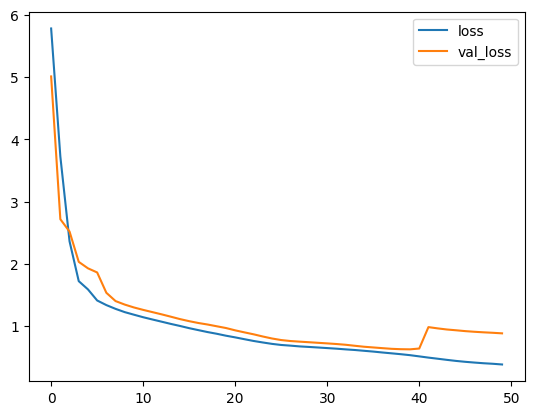

In [ ]:
graf=pd.DataFrame(history1.history)
graf=graf.drop(["val_accuracy","accuracy"],axis=1)
graf.plot()

In [ ]:
y_pred = model_1.predict(scaled_x_test)
y_pred=(y_pred>0.5).astype(int)
print("Accuracy is",accuracy_score(y_test,y_pred))
print("Precision is",precision_score(y_test,y_pred))
print("Recall is",recall_score(y_test,y_pred))
print("F1 score is",f1_score(y_test,y_pred))
print("Confusion matrix is"+"\n", confusion_matrix(y_test,y_pred))
print("")
print(classification_report(y_test,y_pred))

1/1 [==============================] - 0s 253ms/step
Accuracy is 0.8333333333333334
Precision is 0.7647058823529411
Recall is 0.9285714285714286
F1 score is 0.8387096774193549
Confusion matrix is
 [[12  4]
 [ 1 13]]

              precision    recall  f1-score   support

           0       0.92      0.75      0.83        16
           1       0.76      0.93      0.84        14

    accuracy                           0.83        30
   macro avg       0.84      0.84      0.83        30
weighted avg       0.85      0.83      0.83        30



In [ ]:
#early_stop = EarlyStopping(monitor='val_loss', patience=10)

In [ ]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])